# Kiểm tra feature và cách diễn giải kết quả

Đối chiếu bộ feature, mô hình boosting và calibration trên train. Phần cuối dùng lại Random Forest và ngưỡng đã chốt ở [tuần 3](03_evaluation.ipynb) để ước lượng bất định trên test. Các mô hình và phương án bổ sung chỉ được so sánh trên train.

## 1. Cùng một split và bộ fold train

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score, brier_score_loss, log_loss, precision_score, recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from threadpoolctl import threadpool_limits

from project_model import CATEGORICAL_COLUMNS, THRESHOLD, load_train, make_forest

X, y = load_train()
data = pd.read_csv("data/online_shoppers_intention.csv")
group_sizes = X.groupby(list(X.columns), sort=False, dropna=False)
groups = group_sizes.ngroup()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X, y, groups))
assert all(not groups.iloc[fit].isin(groups.iloc[val]).any() for fit, val in folds)
print(f"{len(X):,} phiên train, {X.shape[1]} feature, {groups.nunique():,} nhóm.")

9,864 phiên train, 16 feature, 9,773 nhóm.


## 2. Kiểm tra `PageValues`, bộ biến ngữ cảnh và gradient boosting

So sánh trên cùng năm fold, với nhóm cố định theo 16 feature gốc. Random Forest giữ nguyên siêu tham số. UCI mô tả `PageValues` là chỉ số giá trị trang có liên hệ với giao dịch. Phép so sánh đo ảnh hưởng của cột này lên AP trong dataset. Thời điểm tính và khả năng có sẵn của chỉ số cần được xác minh riêng. [Mô tả UCI](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)

Bộ biến ngữ cảnh gồm tháng, hệ điều hành, trình duyệt, vùng, loại nguồn truy cập, loại khách, cuối tuần và `SpecialDay`. Phép thử đo hiệu năng khi bỏ các biến tổng hợp hành vi. CSV thiếu timestamp và chuỗi sự kiện theo phiên để dựng feature tại một lượt xem cụ thể. [Nghiên cứu dự đoán sớm theo lượt tương tác](https://link.springer.com/article/10.1007/s12525-020-00448-x)

Thử một cấu hình `HistGradientBoostingClassifier` trên 16 feature chính, có xử lý biến phân loại theo dtype. Đây là một kết quả thăm dò trên train. [Tài liệu scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html)

In [2]:
context_columns = [*CATEGORICAL_COLUMNS, "SpecialDay"]
context = X[context_columns]
plus_page_values = X.assign(PageValues=data.loc[X.index, "PageValues"])

def categorical_dtype(frame):
    return frame.astype({column: "category" for column in CATEGORICAL_COLUMNS})

boosting = make_pipeline(
    FunctionTransformer(categorical_dtype),
    HistGradientBoostingClassifier(
        max_iter=100, learning_rate=0.1, max_leaf_nodes=31, random_state=42,
    ),
)
experiments = [
    ("Random Forest · 16 feature", make_forest(X.columns), X),
    ("Random Forest · thêm PageValues", make_forest(plus_page_values.columns), plus_page_values),
    ("Random Forest · 8 biến ngữ cảnh", make_forest(context.columns), context),
    ("HistGradientBoosting · 16 feature", boosting, X),
]

results = []
for name, estimator, features in experiments:
    with threadpool_limits(limits=2):
        probabilities = cross_val_predict(
            estimator, features, y, cv=folds, method="predict_proba", n_jobs=1,
        )[:, 1]
    ap = np.array([average_precision_score(y.iloc[val], probabilities[val]) for _, val in folds])
    results.append({
        "Cấu hình": name, "AP trung bình": ap.mean(), "Độ lệch chuẩn": ap.std(),
        **{f"Fold {i}": value for i, value in enumerate(ap, start=1)},
    })
    if name == experiments[0][0]:
        raw_oof = probabilities
display(pd.DataFrame(results).round(5))

,Cấu hình,AP trung bình,Độ lệch chuẩn,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
0,Random Forest · 16 feature,0.38277,0.02026,0.37075,0.39437,0.39551,0.34889,0.40431
1,Random Forest · thêm PageValues,0.74265,0.01810,0.74630,0.74959,0.73894,0.71147,0.76695
2,Random Forest · 8 biến ngữ cảnh,0.26739,0.01231,0.26656,0.24665,0.27798,0.26409,0.28168
3,HistGradientBoosting · 16 feature,0.35902,0.02126,0.36130,0.37356,0.32696,0.34544,0.38786


## 3. Độ tin cậy của điểm mua

So sánh xác suất Random Forest gốc với calibration sigmoid. Trong mỗi fold ngoài, tạo bốn fold theo nhóm từ phần fit ngoài. Calibration học từ các dự đoán OOF nội bộ, rồi mô hình fit lại trên phần fit ngoài. Phần validation ngoài chỉ dùng để đo. Baseline dự đoán tỷ lệ mua của phần fit ngoài cho mọi phiên validation của fold đó.

Brier loss và log loss càng thấp càng tốt. Biểu đồ calibration so sánh điểm dự đoán trung bình với tỷ lệ mua quan sát thực tế. Chia thành năm khoảng theo phân vị riêng của mỗi phương án. Điểm trên biểu đồ dùng để đánh giá độ tin cậy của điểm mua. Ngưỡng và mô hình test đã chốt vẫn sử dụng điểm gốc. [Tài liệu calibration](https://scikit-learn.org/stable/modules/calibration.html)

,Phương án,Brier loss,Log loss
0,Random Forest gốc,0.11315,0.36059
1,Sigmoid,0.11361,0.36560
2,Tỷ lệ mua phần fit,0.13077,0.43078


Random Forest gốc · nhóm điểm cao nhất: điểm 33.10%, tỷ lệ mua 36.64%
Sigmoid · nhóm điểm cao nhất: điểm 38.27%, tỷ lệ mua 36.59%


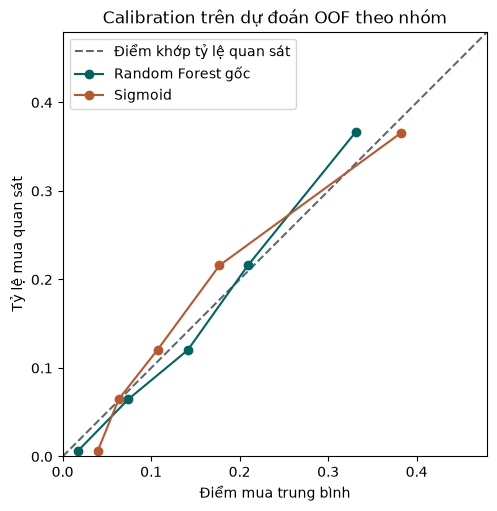

In [3]:
sigmoid_oof = np.empty(len(y))
prior_oof = np.empty(len(y))
for fit, val in folds:
    inner_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
    inner = list(inner_cv.split(X.iloc[fit], y.iloc[fit], groups.iloc[fit]))
    fit_groups = groups.iloc[fit]
    assert all(not fit_groups.iloc[a].isin(fit_groups.iloc[b]).any() for a, b in inner)
    calibrated = CalibratedClassifierCV(
        make_forest(X.columns), method="sigmoid", cv=inner, ensemble=False, n_jobs=1,
    )
    calibrated.fit(X.iloc[fit], y.iloc[fit])
    sigmoid_oof[val] = calibrated.predict_proba(X.iloc[val])[:, 1]
    prior_oof[val] = y.iloc[fit].mean()

methods = [("Random Forest gốc", raw_oof), ("Sigmoid", sigmoid_oof), ("Tỷ lệ mua phần fit", prior_oof)]
display(pd.DataFrame([
    {"Phương án": name, "Brier loss": brier_score_loss(y, scores), "Log loss": log_loss(y, scores)}
    for name, scores in methods
]).round(5))

fig, ax = plt.subplots(figsize=(6.6, 5), layout="constrained")
ax.plot([0, 1], [0, 1], "--", color="#596C76", label="Điểm khớp tỷ lệ quan sát")
for (name, scores), color in zip(methods[:2], ["#006560", "#B9572D"]):
    observed, predicted = calibration_curve(y, scores, n_bins=5, strategy="quantile")
    print(f"{name} · nhóm điểm cao nhất: điểm {predicted[-1]:.2%}, tỷ lệ mua {observed[-1]:.2%}")
    ax.plot(predicted, observed, marker="o", color=color, label=name)
limit = 0.48
ax.set(xlim=(0, limit), ylim=(0, limit), title="Calibration trên dự đoán OOF theo nhóm",
       xlabel="Điểm mua trung bình", ylabel="Tỷ lệ mua quan sát")
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

## 4. Khoảng bootstrap 95% cho mô hình test đã chốt

Fit lại đúng Random Forest tuần 3 một lần và dùng ngưỡng đã lưu. Lấy mẫu có hoàn lại theo các nhóm giống nhau trên 16 feature trong test. Dùng số lần mỗi nhóm được chọn làm trọng số chung cho các dòng trong nhóm. Mỗi lần lặp giữ cặp nhãn và điểm dự đoán cùng nhau. Khoảng percentile từ 2,5% đến 97,5% qua 2.000 lượt mô tả độ biến động do lấy mẫu test, với giả định các nhóm độc lập. Khoảng này giữ mô hình và ngưỡng cố định. [Phương pháp bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)

In [4]:
split = json.loads(Path("data/split_indices.json").read_text(encoding="utf-8"))
test = data.iloc[split["test_indices"]]
X_test, y_test = test[X.columns], test["Revenue"]
fixed_model = make_forest(X.columns).fit(X, y)
scores = fixed_model.predict_proba(X_test)[:, 1]
predictions = scores >= THRESHOLD

def measure(weights=None):
    return [
        average_precision_score(y_test, scores, sample_weight=weights),
        precision_score(y_test, predictions, sample_weight=weights),
        recall_score(y_test, predictions, sample_weight=weights),
    ]

test_groups = X_test.groupby(list(X_test.columns), sort=False, dropna=False).ngroup().to_numpy()
n_groups = len(np.unique(test_groups))
rng = np.random.default_rng(42)
draws = []
for _ in range(2000):
    chosen = rng.integers(n_groups, size=n_groups)
    group_weights = np.bincount(chosen, minlength=n_groups)
    draws.append(measure(group_weights[test_groups]))

lower, upper = np.quantile(draws, [0.025, 0.975], axis=0)
display(pd.DataFrame({
    "Ước lượng trên test": measure(), "Cận dưới 95%": lower, "Cận trên 95%": upper,
}, index=["Average Precision", "Precision lớp mua", "Recall lớp mua"]).round(5))

matches = X_test.merge(X.drop_duplicates(), how="inner", on=list(X.columns))
print(f"{len(test):,} phiên test, {n_groups:,} nhóm, {len(matches)} phiên có vector trùng với train.")

,Ước lượng trên test,Cận dưới 95%,Cận trên 95%
Average Precision,0.35424,0.31007,0.40529
Precision lớp mua,0.30299,0.26944,0.33653
Recall lớp mua,0.58377,0.53196,0.63232


2,466 phiên test, 2,454 nhóm, 29 phiên có vector trùng với train.
